**Import Libary**

In [ ]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score)
from scipy.cluster.hierarchy import linkage,dendrogram

**Load The Dataset**

In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)
df=pd.read_csv('Wholesale customers data.csv')

**EDA**

In [ ]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [ ]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [ ]:
df.shape

(440, 8)

In [ ]:
df.dtypes

,0
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [ ]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [ ]:
df.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.columns

Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen'],
      dtype='object')

**Algorithm**

In [ ]:
features=['Fresh', 'Milk', 'Grocery', 'Frozen','Detergents_Paper', 'Delicassen']
X=df[features].copy()
display(X.head())
print("Number of records used for clustering:",len(X))

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


Number of records used for clustering: 440


In [ ]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

In [ ]:
X_scaled_df=pd.DataFrame(X_scaled,columns=features, index=X.index)

In [ ]:
display(X_scaled_df.head())

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


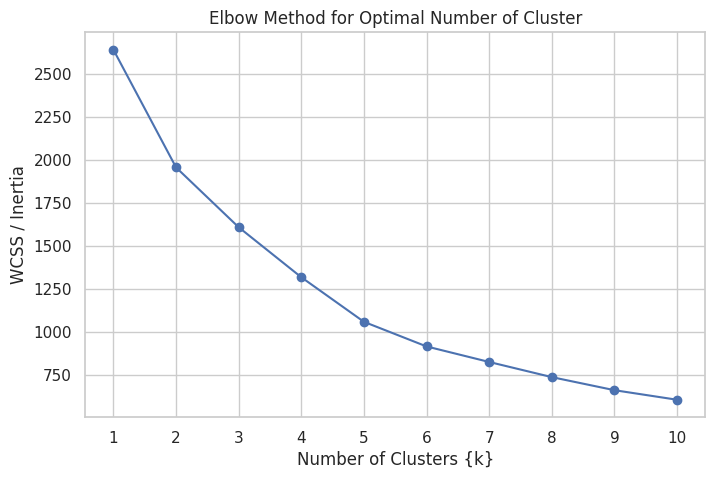

In [ ]:
wcss=[]
k_values=range(1,11)
for k in k_values:
    kmeans=KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
plt.figure(figsize=(8,5))
plt.plot(list(k_values),wcss,marker="o")
plt.xlabel("Number of Clusters {k}")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method for Optimal Number of Cluster")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [ ]:
silhouette_values=[]
for k in range(2,11):
    model=KMeans(n_clusters=k,random_state=42,n_init=10)
    labels=model.fit_predict(X_scaled)
    score=silhouette_score(X_scaled,labels)
    silhouette_values.append(score)
silhouette_table=pd.DataFrame({
    'Number of Clusters':range(2,11),
    'Silhouette Score':silhouette_values
})
display(silhouette_table.round(4))

,Number of Clusters,Silhouette Score
0,2,0.5472
1,3,0.5483
2,4,0.3485
3,5,0.3690
4,6,0.3782
5,7,0.3343
6,8,0.3201
7,9,0.3090
8,10,0.3112


In [ ]:
suggested_k=int(
    silhouette_table.loc[
        silhouette_table['Silhouette Score'].idxmax(),'Number of Clusters'])
print("K suggested by the highest silhouette score:",suggested_k)

K suggested by the highest silhouette score: 3


In [ ]:
K=suggested_k
kmeans_model=KMeans(n_clusters=K,random_state=42,n_init=10)
kmeans_labels=kmeans_model.fit_predict(X_scaled)

In [ ]:
df_kmeans=df.copy()
df_kmeans["KMeans_Cluster"]=kmeans_labels
print("K-Mean clustering completed")
print("\nNumber of customer in each cluster:")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())
print("\nSample records with labels:")
display(df_kmeans.head())

K-Mean clustering completed

Number of customer in each cluster:
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64

Sample records with labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


In [ ]:
hierarchical_model=AgglomerativeClustering(
    n_clusters=K,
    linkage="ward",
    metric="euclidean"
)
hierarchical_labels=hierarchical_model.fit_predict(X_scaled)

In [ ]:
df_hierarchical=df.copy()
df_hierarchical["Hierarchical_Cluster"]=hierarchical_labels
print("Hierarchical clustering completed")
print("\nNumber of customer in each cluster:")
print(df_hierarchical["Hierarchical_Cluster"].value_counts().sort_index())
print("\nSample records with labels:")
display(df_hierarchical.head())

Hierarchical clustering completed

Number of customer in each cluster:
Hierarchical_Cluster
0      6
1    281
2    153
Name: count, dtype: int64

Sample records with labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Hierarchical_Cluster
0,2,3,12669,9656,7561,214,2674,1338,2
1,2,3,7057,9810,9568,1762,3293,1776,2
2,2,3,6353,8808,7684,2405,3516,7844,2
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


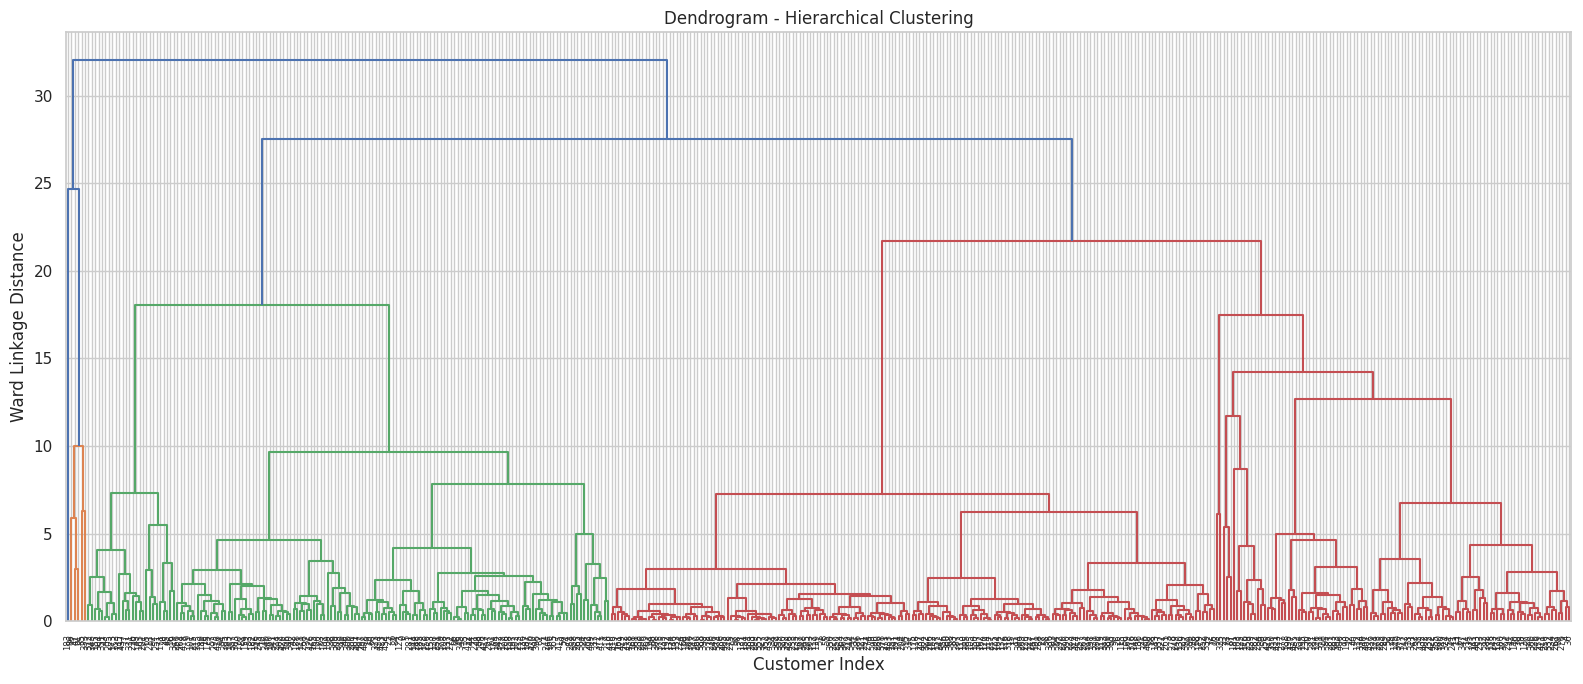

In [ ]:
Z=linkage(X_scaled,method="ward",metric="euclidean")
plt.figure(figsize=(16,7))
dendrogram(Z,leaf_rotation=90,leaf_font_size=6)
plt.title("Dendrogram - Hierarchical Clustering")
plt.xlabel("Customer Index")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

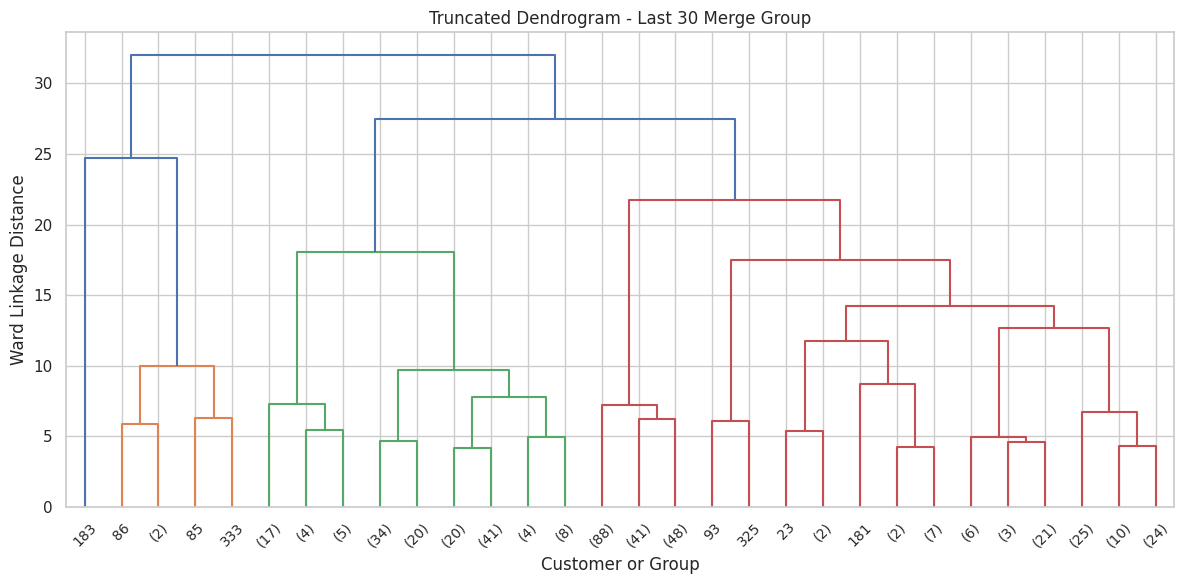

In [ ]:
plt.figure(figsize=(12,6))
dendrogram(Z,truncate_mode='lastp',p=30,show_leaf_counts=True,leaf_rotation=45)
plt.title("Truncated Dendrogram - Last 30 Merge Group")
plt.xlabel("Customer or Group")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

In [ ]:
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled)
print("Variance explained by the line PCA components:",round(pca.explained_variance_ratio_.sum()*100,2),"%")
plot_df=pd.DataFrame({"PC1": X_pca[:,0], "PC2": X_pca[:,1],
                      "KMeans_Cluster": kmeans_labels.astype(str),
                      "Hierarchical_Cluster": hierarchical_labels.astype(str)
                      })

Variance explained by the line PCA components: 72.46 %


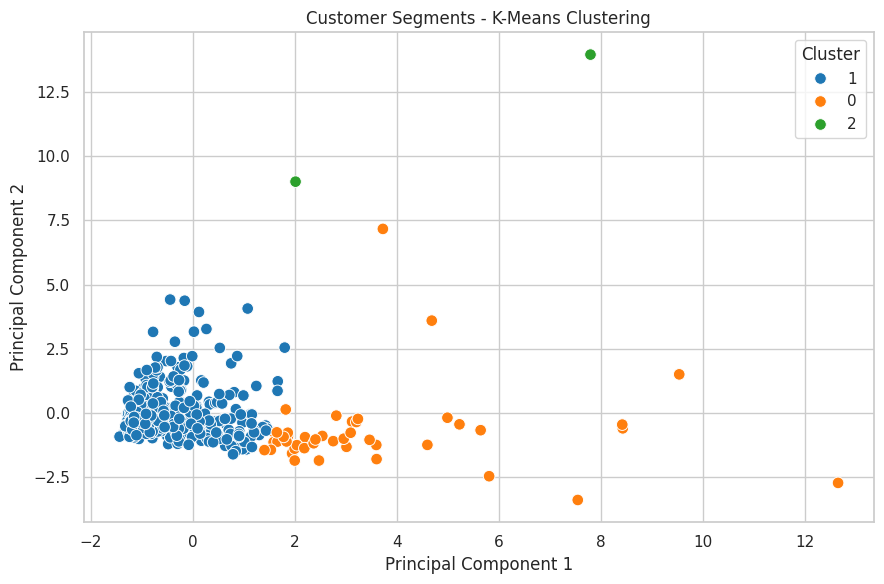

In [ ]:
plt.figure(figsize=(9,6))
sns.scatterplot(data=plot_df,x="PC1",y="PC2",hue="KMeans_Cluster",palette="tab10",s=70)
plt.title("Customer Segments - K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

In [ ]:
def evaluate_clustering(X_data, lables, model_name):
  return{
      "Algorithm":model_name,
      "Number of Clusters":len(np.unique(lables)),
      "Silhouette Score":silhouette_score(X_data,lables),
      "Davies-Bouldin Score":davies_bouldin_score(X_data,lables),
      "Calinski-Harabasz Score":calinski_harabasz_score(X_data,lables)
  }

In [ ]:
cluster_sizes=pd.DataFrame({
    "KMeans":pd.Series(kmeans_labels).value_counts().sort_index(),
    "Hierarchical":pd.Series(hierarchical_labels).value_counts().sort_index()
}).fillna(0).astype(int)
print("Cluster sizes")
display(cluster_sizes)

Cluster sizes


,KMeans,Hierarchical
0,45,6
1,393,281
2,2,153


In [ ]:
kmeans_profile=df[features].copy()
kmeans_profile["Cluster"]=kmeans_labels
kmeans_mean=kmeans_profile.groupby("Cluster")[features].mean().round(2)
print("Average spending profiles of K-Means clusters:")
display(kmeans_mean)

Average spending profiles of K-Means clusters:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10440.93,19386.42,28656.09,2190.24,13327.80,2374.20
1,12062.91,4115.10,5534.97,2940.68,1696.17,1299.11
2,34782.00,30367.00,16898.00,48701.50,755.50,26776.00


In [ ]:
cluster_distribution=pd.DataFrame({
    "Customer Count":pd.Series(kmeans_labels).value_counts().sort_index()
})
cluster_distribution["Percentage"]=(cluster_distribution["Customer Count"]/len(df)*100).round(2)
print("K-Means customer distribution")
display(cluster_distribution)

K-Means customer distribution


,Customer Count,Percentage
0,45,10.23
1,393,89.32
2,2,0.45


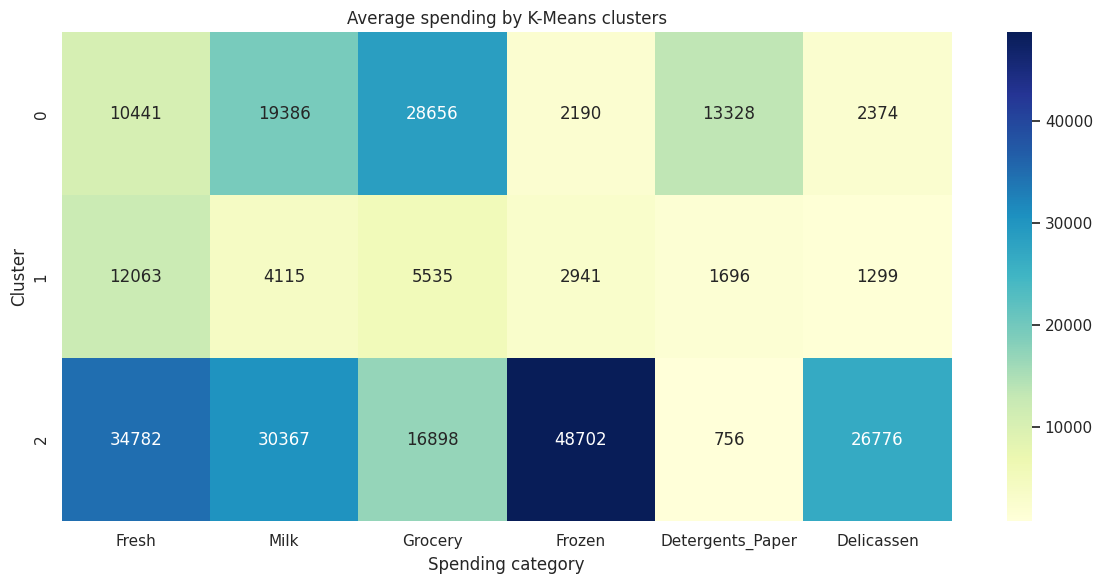

In [ ]:
plt.figure(figsize=(12,6))
sns.heatmap(kmeans_mean,annot=True,cmap="YlGnBu",fmt=".0f")
plt.title("Average spending by K-Means clusters")
plt.xlabel("Spending category")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

In [ ]:
channel_mlx=pd.crosstab(df["Channel"],kmeans_labels,normalize="columns")*100
channel_mlx.columns=[f"Cluster {c}" for c in channel_mlx.columns]
print("Channel composition within each K-Means cluster (%):")
display(channel_mlx.round(2))

Channel composition within each K-Means cluster (%):


,Cluster 0,Cluster 1,Cluster 2
Channel,,,
1,2.22,75.06,100.0
2,97.78,24.94,0.0
